# 📘 3.3 Newton Polynomial Interpolation

### Building an interpolating polynomials one data point at a time

In Notebook 3.1, we introduced interpolation as a method for estimating values between measured data points.

In Notebook 3.2, we saw that exact interpolation can be risky when the data contains noise.

In this notebook, we focus on one classical exact interpolation method:

> **Newton polynomial interpolation**

Newton polynomial interpolation constructs a polynomial that passes through a set of known data points. It is especially useful for learning because it shows how interpolation can be built progressively using a **divided difference table**.

We will use the same rocket velocity dataset from Notebook 3.1 and estimate the velocity at times that were not directly measured.

### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* write the general form of a Newton interpolating polynomial;
* explain what divided differences are;
* construct a divided difference table in Python;
* evaluate a Newton interpolating polynomial at a query point;
* compare Newton interpolants of different degree;
* explain why high-degree global polynomial interpolation should be used carefully.

### 🔗 Unit Learning Outcome Alignment

This notebook supports the following MMA3001 learning outcomes:

* **LO2:** Demonstrate effective use of numerical analysis and machine learning tools to develop defensible solutions to open-ended engineering problems.
* **LO3:** Apply appropriate mathematical and numerical techniques to solve common engineering problems, and evaluate program performance, error, stability and accuracy.

### 📚 Sources used in this notebook

The main technical ideas and example structure in this notebook are based on:

* Python Numerical Methods — Newton's Polynomial Interpolation  
  https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter17.05-Newtons-Polynomial-Interpolation.html

* Holistic Numerical Methods — Newton Divided Difference Method  
  https://nm.mathforcollege.com/chapter-05-03-newton-divided-difference-method/

* Holistic Numerical Methods textbook — Newton's Divided Difference Method of Interpolation  
  https://nm.mathforcollege.com/NumericalMethodsTextbookUnabridged/chapter-05.03-newtons-divided-difference-method-of-interpolation.html

* SciPy User Guide — Interpolation  
  https://docs.scipy.org/doc/scipy/tutorial/interpolate.html

* SciPy API Reference — BarycentricInterpolator  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.BarycentricInterpolator.html

* UBC — The Runge Phenomenon and Piecewise Polynomial Interpolation  
  https://www.math.ubc.ca/~peirce/M406_Lecture_3_Runge_Phenon_Piecewise_Polynomial_Interpolation.pdf

## 📂 3.3.0 How to use this notebook

This is a **pre-work content notebook**. Run every code cell from top to bottom; no cell
requires editing or typed input.

The separate Week 3 workbook contains the activities to begin in Monday's workshop,  continue in Wednesday's practical, and finish during revision at home.


## 📂 3.3.1 What is Newton polynomial interpolation?

Suppose we have $n+1$ data points:

$$
(x_0, y_0), (x_1, y_1), \dots, (x_n, y_n)
$$

Newton polynomial interpolation constructs a polynomial $P_n(x)$ of degree at most $n$ that passes through every data point:

$$
P_n(x_i) = y_i
$$

for every data point $i$.

The Newton form of the polynomial is:

$$
P_n(x)
=
a_0
+
a_1(x - x_0)
+
a_2(x - x_0)(x - x_1)
+
\dots
+
a_n(x - x_0)(x - x_1)\dots(x - x_{n-1})
$$

The coefficients $a_0, a_1, \dots, a_n$ are found using **divided differences**.

### Important idea

Newton interpolation does not create a different interpolating polynomial from Lagrange interpolation. For a given set of data points, the interpolating polynomial is unique.

Newton and Lagrange interpolation are different ways of writing and calculating the same polynomial.

## 📂 3.3.2 Divided differences

The divided differences are the coefficients used in the Newton polynomial.

The zeroth-order divided difference is just the function value:

$$
f[x_i] = y_i
$$

The first-order divided difference between two points is:

$$
f[x_i, x_{i+1}]
=
\frac{f[x_{i+1}] - f[x_i]}{x_{i+1} - x_i}
$$

The second-order divided difference is:

$$
f[x_i, x_{i+1}, x_{i+2}]
=
\frac{
f[x_{i+1}, x_{i+2}]
-
f[x_i, x_{i+1}]
}{
x_{i+2} - x_i
}
$$

More generally:

$$
f[x_i, x_{i+1}, \dots, x_{i+k}]
=
\frac{
f[x_{i+1}, \dots, x_{i+k}]
-
f[x_i, \dots, x_{i+k-1}]
}{
x_{i+k} - x_i
}
$$

The Newton coefficients are taken from the top row of the divided difference table:

$$
a_0 = f[x_0]
$$

$$
a_1 = f[x_0, x_1]
$$

$$
a_2 = f[x_0, x_1, x_2]
$$

and so on.

### ⚠️ Point of note

Newton interpolation requires distinct $x$ values.

If two data points have the same $x$ value but different $y$ values, then there is no single-valued function $y=f(x)$ passing through both of them.

Repeated $x$ values can be handled by other methods such as Hermite interpolation, but that is outside the scope of this notebook.

In [ ]:
from IPython.display import display
# Core imports for this notebook

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import BarycentricInterpolator

pd.set_option("display.precision", 6)

## 📂 3.3.3 Example dataset: rocket velocity

We will use the same rocket velocity dataset introduced in Notebook 3.1.

The data gives upward velocity as a function of time.

This is an interpolation problem because we want to estimate velocity values between measured time samples.

In [ ]:
# Rocket velocity data
# Source: Autar Kaw / Holistic Numerical Methods rocket interpolation example

time_s = np.array([0, 10, 15, 20, 22.5, 30], dtype=float)
velocity_ms = np.array([0, 227.04, 362.78, 517.35, 602.97, 901.67], dtype=float)

rocket_data = pd.DataFrame({
    "time_s": time_s,
    "velocity_ms": velocity_ms
})

rocket_data

,time_s,velocity_ms
0,0.0,0.00
1,10.0,227.04
2,15.0,362.78
3,20.0,517.35
4,22.5,602.97
5,30.0,901.67


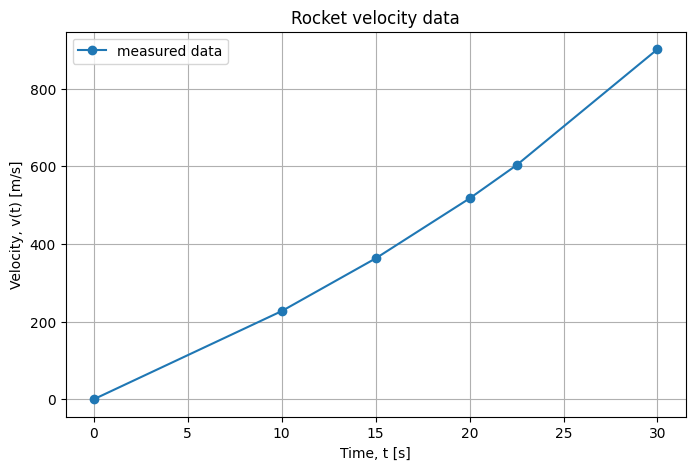

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(time_s, velocity_ms, "o-", label="measured data")

ax.set_xlabel("Time, t [s]")
ax.set_ylabel("Velocity, v(t) [m/s]")
ax.set_title("Rocket velocity data")
ax.grid(True)
ax.legend()

plt.show()

## 📂 3.3.4 Building the divided difference table

The following functions will:

1. build a divided difference table;
2. extract the Newton polynomial coefficients;
3. evaluate the Newton polynomial at query points;
4. display the divided difference table as a `pandas` DataFrame.

The evaluation function uses a nested multiplication form. This is similar in spirit to Horner's method and avoids explicitly expanding the polynomial into powers of $x$.

In [ ]:
def divided_difference_table(x, y):
    """
    Build a divided difference table for Newton polynomial interpolation.

    Parameters
    ----------
    x : array-like
        Independent variable values.

    y : array-like
        Dependent variable values.

    Returns
    -------
    numpy.ndarray
        Square divided difference table.
        The first column contains y values.
        The top row contains the Newton coefficients.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if x.ndim != 1 or y.ndim != 1:
        raise ValueError("x and y must be one-dimensional arrays.")

    if x.size != y.size:
        raise ValueError("x and y must have the same length.")

    if np.unique(x).size != x.size:
        raise ValueError("x values must be distinct for divided differences.")

    n = x.size
    table = np.full((n, n), np.nan, dtype=float)

    # Zeroth-order divided differences are the y values.
    table[:, 0] = y

    # Higher-order divided differences.
    for order in range(1, n):
        for row in range(n - order):
            numerator = table[row + 1, order - 1] - table[row, order - 1]
            denominator = x[row + order] - x[row]
            table[row, order] = numerator / denominator

    return table


def newton_coefficients(x, y):
    """
    Return Newton coefficients and the full divided difference table.
    """
    table = divided_difference_table(x, y)
    coefficients = table[0, :]
    return coefficients, table


def newton_evaluate(x_query, x_nodes, coefficients):
    """
    Evaluate a Newton interpolating polynomial.

    Parameters
    ----------
    x_query : float or array-like
        Location or locations where the polynomial should be evaluated.

    x_nodes : array-like
        x values used to construct the Newton polynomial.

    coefficients : array-like
        Newton coefficients from the top row of the divided difference table.

    Returns
    -------
    float or numpy.ndarray
        Predicted value or values.
    """
    x_nodes = np.asarray(x_nodes, dtype=float)
    coefficients = np.asarray(coefficients, dtype=float)
    x_query_array = np.asarray(x_query, dtype=float)

    # Start from the highest-order coefficient.
    result = np.zeros_like(x_query_array, dtype=float) + coefficients[-1]

    # Work backwards through the coefficients.
    for k in range(len(coefficients) - 2, -1, -1):
        result = coefficients[k] + (x_query_array - x_nodes[k]) * result

    if np.isscalar(x_query):
        return float(result)

    return result


def divided_difference_dataframe(x, table):
    """
    Convert a divided difference table into a labelled pandas DataFrame.
    """
    n = len(x)
    columns = ["f[x_i]"] + [f"order_{j}" for j in range(1, n)]

    df = pd.DataFrame(table, columns=columns)
    df.insert(0, "x_i", x)

    return df

## 📂 3.3.5 Cubic Newton interpolation near $t=16$ s

Suppose we want to estimate the rocket velocity at:

$$
t = 16 \text{ s}
$$

A sensible local set of nearby points is:

$$
t = 10,\ 15,\ 20,\ 22.5 \text{ s}
$$

Using four points gives a cubic interpolating polynomial.

In [ ]:
local_x = np.array([10, 15, 20, 22.5], dtype=float)
local_y = np.array([227.04, 362.78, 517.35, 602.97], dtype=float)

local_coefficients, local_table = newton_coefficients(local_x, local_y)

local_table_df = divided_difference_dataframe(local_x, local_table)

local_table_df

,x_i,f[x_i],order_1,order_2,order_3
0,10.0,227.04,27.148,0.376600,0.005435
1,15.0,362.78,30.914,0.444533,NaN
2,20.0,517.35,34.248,NaN,NaN
3,22.5,602.97,NaN,NaN,NaN


In [ ]:
local_coefficients

array([2.27040000e+02, 2.71480000e+01, 3.76600000e-01, 5.43466667e-03])

The top row of the divided difference table gives the coefficients:

$$
a_0 = 227.04
$$

$$
a_1 = 27.148
$$

$$
a_2 = 0.376600
$$

$$
a_3 = 0.005435
$$

Therefore, using nodes $10$, $15$, $20$ and $22.5$, the cubic Newton polynomial is:

$$
P_3(t)
=
227.04
+
27.148(t - 10)
+
0.376600(t - 10)(t - 15)
+
0.005435(t - 10)(t - 15)(t - 20)
$$

This polynomial passes through the four selected data points.

In [ ]:
t_query = 16.0

v_query = newton_evaluate(
    t_query,
    local_x,
    local_coefficients
)

print(f"Predicted velocity at t = {t_query:.1f} s: {v_query:.3f} m/s")

Predicted velocity at t = 16.0 s: 392.057 m/s


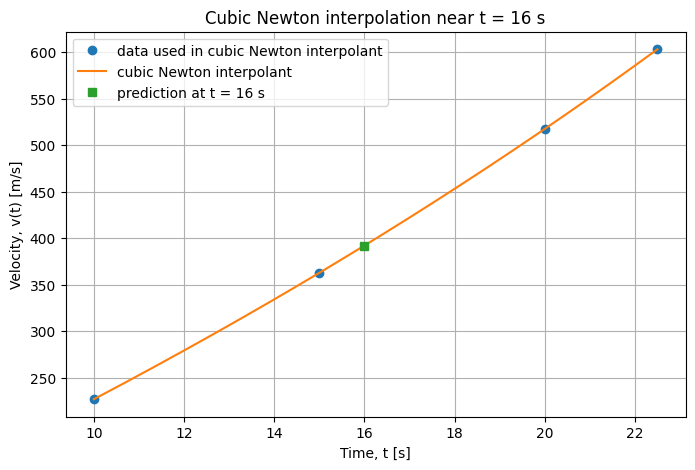

In [ ]:
t_plot = np.linspace(10, 22.5, 300)

v_plot = newton_evaluate(
    t_plot,
    local_x,
    local_coefficients
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(local_x, local_y, "o", label="data used in cubic Newton interpolant")
ax.plot(t_plot, v_plot, label="cubic Newton interpolant")
ax.plot(t_query, v_query, "s", label=f"prediction at t = {t_query:g} s")

ax.set_xlabel("Time, t [s]")
ax.set_ylabel("Velocity, v(t) [m/s]")
ax.set_title("Cubic Newton interpolation near t = 16 s")
ax.grid(True)
ax.legend()

plt.show()

> ### 🧩 Code Explanation
>
> The function `newton_coefficients` builds the divided difference table and extracts the coefficients from the top row.
>
> The function `newton_evaluate` evaluates the polynomial without expanding it into a standard power-series form.
>
> For the four selected points, the resulting polynomial is cubic because four points define a polynomial of degree at most three.

## 📂 3.3.6 Comparing different interpolation orders

The interpolation order depends on how many data points are used.

| Number of points | Polynomial degree |
|---:|---:|
| 2 | 1, linear |
| 3 | 2, quadratic |
| 4 | 3, cubic |
| 6 | 5, full global polynomial |

A higher-degree polynomial is not automatically better.

Higher degree means more flexibility, but it can also mean more oscillation and greater sensitivity to data errors.

In [ ]:
node_sets = {
    "linear, 2 points": np.array([15, 20], dtype=float),
    "quadratic, 3 points": np.array([10, 15, 20], dtype=float),
    "cubic, 4 points": np.array([10, 15, 20, 22.5], dtype=float),
    "full degree 5, 6 points": time_s
}

comparison_rows = []

for label, nodes in node_sets.items():
    mask = np.isin(time_s, nodes)

    x_nodes = time_s[mask]
    y_nodes = velocity_ms[mask]

    coefficients, table = newton_coefficients(x_nodes, y_nodes)

    comparison_rows.append({
        "method": label,
        "n_points": len(x_nodes),
        "degree": len(x_nodes) - 1,
        "v_at_16_ms": newton_evaluate(16.0, x_nodes, coefficients)
    })

order_comparison = pd.DataFrame(comparison_rows)

order_comparison

,method,n_points,degree,v_at_16_ms
0,"linear, 2 points",2,1,393.694000
1,"quadratic, 3 points",3,2,392.187600
2,"cubic, 4 points",4,3,392.057168
3,"full degree 5, 6 points",6,5,392.070579


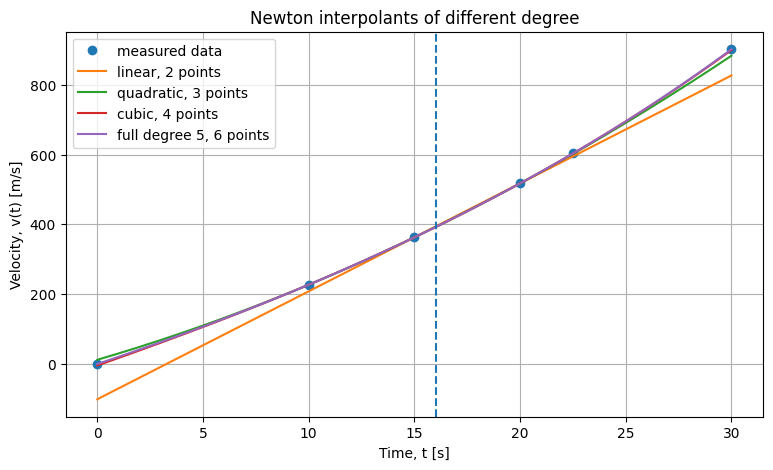

In [ ]:
t_plot = np.linspace(0, 30, 500)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(time_s, velocity_ms, "o", label="measured data")

for label, nodes in node_sets.items():
    mask = np.isin(time_s, nodes)

    x_nodes = time_s[mask]
    y_nodes = velocity_ms[mask]

    coefficients, table = newton_coefficients(x_nodes, y_nodes)

    ax.plot(
        t_plot,
        newton_evaluate(t_plot, x_nodes, coefficients),
        label=label
    )

ax.axvline(16, linestyle="--")

ax.set_xlabel("Time, t [s]")
ax.set_ylabel("Velocity, v(t) [m/s]")
ax.set_title("Newton interpolants of different degree")
ax.grid(True)
ax.legend()

plt.show()

### 🧠 What should you notice?

The linear, quadratic, cubic and full degree-5 interpolants give similar predictions near $t=16$ s for this dataset.

However, this does not prove that high-degree interpolation is always safe.

The full degree-5 polynomial is a **global** interpolant. It uses every data point, so every data point affects the whole curve.

For larger datasets, high-degree global polynomial interpolation can behave poorly, especially near boundaries or when the data is noisy.

This is one reason engineers often prefer local interpolation or spline interpolation for practical lookup tables.

## 📂 3.3.7 Comparing our Newton implementation with SciPy

SciPy does not usually require us to manually implement Newton interpolation.

For practical polynomial interpolation, SciPy provides tools such as `BarycentricInterpolator`.

The barycentric form is mathematically related to Lagrange interpolation, not Newton interpolation, but it constructs the same unique interpolating polynomial for the same set of points.

Here we use it as a cross-check for our Newton implementation.

In [ ]:
full_coefficients, full_table = newton_coefficients(time_s, velocity_ms)

barycentric_interpolator = BarycentricInterpolator(time_s, velocity_ms)

check_times = np.array([12, 16, 25], dtype=float)

newton_predictions = newton_evaluate(
    check_times,
    time_s,
    full_coefficients
)

barycentric_predictions = barycentric_interpolator(check_times)

check_table = pd.DataFrame({
    "time_s": check_times,
    "newton_ms": newton_predictions,
    "scipy_barycentric_ms": barycentric_predictions,
    "absolute_difference": np.abs(newton_predictions - barycentric_predictions)
})

check_table

,time_s,newton_ms,scipy_barycentric_ms,absolute_difference
0,12.0,279.296828,279.296828,1.136868e-13
1,16.0,392.070579,392.070579,5.684342e-14
2,25.0,695.011389,695.011389,3.410605e-13


### 🧠 Interpretation

The Newton and SciPy barycentric predictions should be extremely close.

Small nonzero differences may appear because computers use floating-point arithmetic.

This is a useful reminder:

> Two mathematically equivalent algorithms may give slightly different numerical results on a computer.

## 📂 3.3.8 Why Newton form is useful

The Newton form has an important practical advantage:

> If a new data point is added, the existing lower-order coefficients can be reused.

This makes Newton interpolation useful for teaching and for situations where data points are added progressively.

In contrast, some other polynomial forms may require more work to rebuild when a new point is added.

In [ ]:
incremental_rows = []

for n_points in range(2, len(time_s) + 1):
    x_nodes = time_s[:n_points]
    y_nodes = velocity_ms[:n_points]

    coefficients, table = newton_coefficients(x_nodes, y_nodes)

    incremental_rows.append({
        "n_points": n_points,
        "degree": n_points - 1,
        "newest_coefficient": coefficients[-1],
        "v_at_16_ms": newton_evaluate(16.0, x_nodes, coefficients)
    })

incremental_table = pd.DataFrame(incremental_rows)

incremental_table

,n_points,degree,newest_coefficient,v_at_16_ms
0,2,1,22.704000,363.264000
1,3,2,0.296267,391.705600
2,4,3,0.004017,392.091200
3,5,4,0.000063,392.066999
4,6,5,0.000001,392.070579


### 🧠 What should you notice?

As more points are added, the interpolating polynomial changes.

The prediction at $t=16$ s also changes.

In this example, the prediction becomes fairly stable after several points. That is useful, but it is not guaranteed for all datasets.

If adding a new data point causes a large change in the prediction, that may indicate:

* the new point is influential;
* the polynomial degree is becoming too high;
* the data has noise or inconsistency;
* the prediction is being made in a sensitive region of the domain.

## 📂 3.3.9 Engineering cautions

Newton polynomial interpolation is a useful method, but it must be used with care.

### Caution 1 — Exact interpolation is not always appropriate

If the data is noisy, exact interpolation may chase the noise.

This was the main lesson from Notebook 3.2.

### Caution 2 — High-degree global polynomials can oscillate

A high-degree polynomial that passes through many data points may oscillate strongly between the points or near the edges of the interval.

This is related to **Runge's phenomenon**.

### Caution 3 — Extrapolation remains risky

Newton interpolation may still produce a number outside the data range.

That number is an extrapolation and should be treated with caution.

### Caution 4 — The polynomial form matters numerically

Expanding a high-degree polynomial into powers of $x$ can be numerically unstable.

The Newton nested form is better than naive expansion, but it does not remove the deeper risks of high-degree interpolation.

## 📂 3.3.10 Worked extension — build and evaluate your own Newton interpolant

Use the code below to investigate how the choice of data points affects the prediction.

### Instructions

1. Change `student_x` and `student_y` to use a different set of rocket data points.
2. Change `student_query`.
3. Rerun the cell.
4. Decide whether your prediction is interpolation or extrapolation.
5. Compare your result with another group.

In [ ]:
# Demonstration setting: Change these data points and query value.
# Make sure student_x and student_y have the same length.

student_x = np.array([10, 15, 20, 22.5], dtype=float)
student_y = np.array([227.04, 362.78, 517.35, 602.97], dtype=float)

student_query = 18.0

student_coefficients, student_table = newton_coefficients(student_x, student_y)

student_prediction = newton_evaluate(
    student_query,
    student_x,
    student_coefficients
)

student_table_df = divided_difference_dataframe(student_x, student_table)

display(student_table_df)

print(f"Prediction at x = {student_query:g}: {student_prediction:.6f}")

,x_i,f[x_i],order_1,order_2,order_3
0,10.0,227.04,27.148,0.376600,0.005435
1,15.0,362.78,30.914,0.444533,NaN
2,20.0,517.35,34.248,NaN,NaN
3,22.5,602.97,NaN,NaN,NaN


Prediction at x = 18: 453.001536


### Reflection questions

Answer these in your own words.

1. What polynomial degree did you create?
2. Is your query point interpolation or extrapolation?
3. Which data point is closest to your query point?
4. If you add one more data point, does your prediction change?
5. Would you trust your result more, less, or the same after adding the new point?

## 📂 3.3.11 Worked extension — investigate the effect of adding points

In this activity, you will choose how many rocket data points are used.

Start with `student_n_points = 3`, then try `4`, `5`, and `6`.

### Questions

1. How does the prediction at $t=16$ s change?
2. Does the prediction become more stable?
3. Does using all points always seem necessary?
4. What might happen if the data contained measurement noise?

In [ ]:
# Demonstration setting: Try 3, 4, 5, and 6.

student_n_points = 4

student_x_nodes = time_s[:student_n_points]
student_y_nodes = velocity_ms[:student_n_points]

student_coefficients, student_table = newton_coefficients(
    student_x_nodes,
    student_y_nodes
)

student_query_times = np.array([12, 16, 21], dtype=float)

student_predictions = newton_evaluate(
    student_query_times,
    student_x_nodes,
    student_coefficients
)

student_incremental_results = pd.DataFrame({
    "time_s": student_query_times,
    "predicted_velocity_ms": student_predictions
})

display(divided_difference_dataframe(student_x_nodes, student_table))
display(student_incremental_results)

,x_i,f[x_i],order_1,order_2,order_3
0,0.0,0.00,22.704,0.296267,0.004017
1,10.0,227.04,27.148,0.376600,NaN
2,15.0,362.78,30.914,NaN,NaN
3,20.0,517.35,NaN,NaN,NaN


,time_s,predicted_velocity_ms
0,12.0,279.2692
1,16.0,392.0912
2,21.0,550.7887


## 📂 3.3.12 Recommended resources

### Reading

* Python Numerical Methods — Newton's Polynomial Interpolation  
  https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter17.05-Newtons-Polynomial-Interpolation.html

* Holistic Numerical Methods — Newton Divided Difference Method  
  https://nm.mathforcollege.com/chapter-05-03-newton-divided-difference-method/

* Holistic Numerical Methods textbook — Newton's Divided Difference Method of Interpolation  
  https://nm.mathforcollege.com/NumericalMethodsTextbookUnabridged/chapter-05.03-newtons-divided-difference-method-of-interpolation.html

* SciPy User Guide — Interpolation  
  https://docs.scipy.org/doc/scipy/tutorial/interpolate.html

* SciPy API Reference — BarycentricInterpolator  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.BarycentricInterpolator.html

* UBC — The Runge Phenomenon and Piecewise Polynomial Interpolation  
  https://www.math.ubc.ca/~peirce/M406_Lecture_3_Runge_Phenon_Piecewise_Polynomial_Interpolation.pdf

### Videos

* Holistic Numerical Methods — Newton Divided Difference Method  
  https://nm.mathforcollege.com/chapter-05-03-newton-divided-difference-method/

* Numerical Methods: Newton's Divided Difference Interpolation  
  https://www.youtube.com/results?search_query=Newton+divided+difference+interpolation+numerical+methods

## 🤖 AI Acknowledgment

Parts of this notebook were developed with the assistance of AI tools for drafting explanations, code structure, and student prompts.

All technical content, code, references, and examples have been reviewed and adapted for MMA3001 teaching purposes.

Students should treat AI-generated explanations and code as starting points only. Numerical outputs should be checked using plots, tests, documentation, and engineering judgement.